In [1]:
#Import library
import pandas as pd
import math
from collections import Counter
from nltk.util import bigrams, trigrams, ngrams

In [4]:
#Load Dataset
import pandas as pd

# Baca dataset hasil preprocessing
data = pd.read_csv("dataset_processed.csv")

text_column = "processed_text"

# Hapus nilai kosong
data = data.dropna(subset=[text_column])

print(f"Jumlah dokumen: {len(data)}")

Jumlah dokumen: 3376


In [5]:
#Membuat Corpus Token
# Gabungkan seluruh teks menjadi satu string
all_text = " ".join(data[text_column].astype(str))

# Pisahkan teks menjadi token
tokens = all_text.split()

print(f"Total token: {len(tokens)}")
print(f"Contoh token: {tokens[:20]}")

Total token: 811723
Contoh token: ['reporter', 'noverius', 'laoli', 'editor', 'noverius', 'laoli', 'kontan', 'co', 'id', 'jakarta', 'harga', 'emas', 'batang', 'sertifikat', 'antam', 'keluar', 'logam', 'mulia', 'pt', 'aneka']


In [45]:
#Membuat unigram
unigram = Counter(tokens)

print("20 Kata Paling Sering Muncul:")
for word, count in unigram.most_common(20):
    print(f"  {word:<20} : {count}")

20 Kata Paling Sering Muncul:
  saham                : 19707
  rp                   : 13266
  pasar                : 9498
  indonesia            : 8841
  harga                : 7907
  pt                   : 7699
  tbk                  : 6328
  kuat                 : 6311
  nilai                : 5532
  usaha                : 4838
  investor             : 4823
  tingkat              : 4530
  level                : 4400
  turun                : 4307
  ihsg                 : 4052
  dagang               : 4037
  indeks               : 3857
  uang                 : 3823
  triliun              : 3813
  milik                : 3791


In [37]:
#Probabilitas Unigram
total_tokens = sum(unigram.values())

unigram_probability = {
    word: count / total_tokens
    for word, count in unigram.items()
}

print("\n10 Kata dengan Probabilitas Tertinggi:")
sorted_prob = sorted(
    unigram_probability.items(),
    key=lambda x: x[1],
    reverse=True
)
for word, prob in sorted_prob[:10]:
    print(f"  {word:<20} : {prob:.6f}")


10 Kata dengan Probabilitas Tertinggi:
  saham                : 0.024278
  rp                   : 0.016343
  pasar                : 0.011701
  indonesia            : 0.010892
  harga                : 0.009741
  pt                   : 0.009485
  tbk                  : 0.007796
  kuat                 : 0.007775
  nilai                : 0.006815
  usaha                : 0.005960


In [38]:
#Membuat Bigram
bigram_tokens = list(bigrams(tokens))
bigram_frequency = Counter(bigram_tokens)

print("20 Bigram Paling Sering Muncul:")
for bigram, count in bigram_frequency.most_common(20):
    print(f"  {' '.join(bigram):<30} : {count}")

20 Bigram Paling Sering Muncul:
  rp triliun                     : 3748
  rp saham                       : 2969
  rp miliar                      : 2373
  saham pt                       : 1996
  pasar modal                    : 1886
  co id                          : 1715
  kontan co                      : 1709
  harga saham                    : 1628
  id jakarta                     : 1556
  level rp                       : 1447
  saham saham                    : 1418
  suku bunga                     : 1382
  efek indonesia                 : 1378
  bisnis com                     : 1315
  bursa efek                     : 1295
  free float                     : 1148
  cnbc indonesia                 : 1125
  putus investasi                : 1115
  indonesia tbk                  : 1072
  harga emas                     : 1008


In [39]:
#Membuat Trigram
trigram_tokens = list(trigrams(tokens))
trigram_frequency = Counter(trigram_tokens)

print("20 Trigram Paling Sering Muncul:")
for trigram, count in trigram_frequency.most_common(20):
    print(f"  {' '.join(trigram):<40} : {count}")

20 Trigram Paling Sering Muncul:
  kontan co id                             : 1709
  co id jakarta                            : 1556
  bursa efek indonesia                     : 1228
  efek indonesia bei                       : 928
  indeks harga saham                       : 880
  level rp saham                           : 879
  harga saham gabung                       : 878
  rp saham pt                              : 877
  jakarta cnbc indonesia                   : 874
  saham gabung ihsg                        : 858
  baca bisnis com                          : 818
  bisnis com jakarta                       : 775
  rp miliar pt                             : 721
  capai rp triliun                         : 626
  otoritas jasa uang                       : 615
  target harga rp                          : 542
  jasa uang ojk                            : 536
  beli jual saham                          : 530
  putus investasi sepenuh                  : 526
  disclaimer berita tuju         

In [46]:
#Conditional Probability Bigram (Tugas 4: minimal 5 kata/pasangan kata)
def bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)]
    denominator = unigram[word1]

    if denominator == 0:
        return 0.0

    return numerator / denominator

# Uji: 5 pasang kata
pairs = [
    ("harga", "saham"),
    ("pasar", "modal"),
    ("suku", "bunga"),
    ("bursa", "efek"),
    ("belajar", "nlp"),      # tidak ada di corpus -> 0
]
for word1, word2 in pairs:
    prob = bigram_probability(word1, word2)
    print(f"P({word2} | {word1}) = {prob:.6f}   (count bigram = {bigram_frequency[(word1, word2)]})")

P(saham | harga) = 0.205894   (count bigram = 1628)
P(modal | pasar) = 0.198568   (count bigram = 1886)
P(bunga | suku) = 0.974612   (count bigram = 1382)
P(efek | bursa) = 0.455665   (count bigram = 1295)
P(nlp | belajar) = 0.000000   (count bigram = 0)


In [42]:
#Probabilitas Kalimat (Tugas 5: minimal 5 kalimat)
def sentence_probability(sentence):
    words = sentence.lower().split()
    probability = 1.0

    for i in range(len(words) - 1):
        p = bigram_probability(words[i], words[i + 1])
        probability *= p

    return probability

# Uji: kalimat uji (token sudah dalam bentuk preprocessed)
test_sentences = [
    "harga saham gabung ihsg",       # ada di corpus
    "bursa efek indonesia bei",      # ada di corpus
    "otoritas jasa uang ojk",        # ada di corpus
    "indeks harga saham gabung",     # ada di corpus
    "pasar modal indonesia",         # sebagian ada
    "indonesia efek bursa",          # kata ada, urutan dibalik
    "saya belajar nlp",              # tidak ada di corpus
    "harga saham terbang kucing",    # sebagian tidak ada
]

for sentence in test_sentences:
    p = sentence_probability(sentence)
    print(f"P('{sentence}') = {p:.8e}")

P('harga saham gabung ihsg') = 7.38500649e-03
P('bursa efek indonesia bei') = 3.37291990e-02
P('otoritas jasa uang ojk') = 7.04089037e-02
P('indeks harga saham gabung') = 2.19393224e-03
P('pasar modal indonesia') = 2.93735693e-02
P('indonesia efek bursa') = 5.73286248e-07
P('saya belajar nlp') = 0.00000000e+00
P('harga saham terbang kucing') = 0.00000000e+00


In [56]:
#Menghitung Perplexity (Tugas 6: untuk setiap kalimat uji)
def perplexity(probability, N):
    if probability == 0 or probability is None:
        return float("inf")
    return probability ** (-1 / N)

print(f"{'Kalimat':<34}{'P(W)':>14}{'N':>4}{'Perplexity':>14}")
for sentence in test_sentences:
    words = sentence.split()
    prob = sentence_probability(sentence)
    N = len(words) - 1          # jumlah bigram dalam kalimat
    pp = perplexity(prob, N)
    print(f"{sentence:<34}{prob:>14.4e}{N:>4}{pp:>14.4f}")

Kalimat                                     P(W)   N    Perplexity
harga saham gabung ihsg               7.3850e-03   3        5.1351
bursa efek indonesia bei              3.3729e-02   3        3.0950
otoritas jasa uang ojk                7.0409e-02   3        2.4217
indeks harga saham gabung             2.1939e-03   3        7.6959
pasar modal indonesia                 2.9374e-02   2        5.8347
indonesia efek bursa                  5.7329e-07   2     1320.7306
saya belajar nlp                      0.0000e+00   2           inf
harga saham terbang kucing            0.0000e+00   3           inf


In [44]:
#Laplace Smoothing (Tugas 8)
vocab_size = len(unigram)

def smoothed_bigram_probability(word1, word2):
    numerator = bigram_frequency[(word1, word2)] + 1
    denominator = unigram[word1] + vocab_size
    return numerator / denominator

# Bandingkan sebelum dan sesudah smoothing
pairs = [("harga", "saham"), ("pasar", "modal"), ("deep", "learning"), ("belajar", "nlp"), ("saham", "kucing")]
print(f"{'Pasangan':<22}{'Tanpa smoothing':>18}{'Laplace':>16}")
for w1, w2 in pairs:
    raw = bigram_probability(w1, w2)
    smooth = smoothed_bigram_probability(w1, w2)
    print(f"P({w2} | {w1})".ljust(22) + f"{raw:>18.8f}{smooth:>16.8f}")

Pasangan                 Tanpa smoothing         Laplace
P(saham | harga)              0.20589351      0.06620606
P(modal | pasar)              0.19856812      0.07203390
P(learning | deep)            0.00000000      0.00005987
P(nlp | belajar)              0.00000000      0.00005989
P(kucing | saham)             0.00000000      0.00002747


In [50]:
#Sentence Probability dan Perplexity dengan Laplace Smoothing
def smoothed_sentence_logprob(sentence):
    words = sentence.lower().split()
    logp = 0.0
    for i in range(len(words) - 1):
        logp += math.log(smoothed_bigram_probability(words[i], words[i + 1]))
    return logp

def smoothed_perplexity(sentence):
    words = sentence.lower().split()
    N = len(words) - 1
    return math.exp(-smoothed_sentence_logprob(sentence) / N)

print(f"{'Kalimat':<34}{'PP tanpa smoothing':>20}{'P(W) Laplace':>16}{'PP Laplace':>14}")
for sentence in test_sentences:
    N = len(sentence.split()) - 1
    pp_raw = perplexity(sentence_probability(sentence), N)
    p_smooth = math.exp(smoothed_sentence_logprob(sentence))
    pp_smooth = smoothed_perplexity(sentence)
    print(f"{sentence:<34}{pp_raw:>20.4f}{p_smooth:>16.4e}{pp_smooth:>14.4f}")

Kalimat                             PP tanpa smoothing    P(W) Laplace    PP Laplace
harga saham gabung ihsg                         5.1351      7.8543e-05       23.3506
bursa efek indonesia bei                        3.0950      1.7992e-04       17.7136
otoritas jasa uang ojk                          2.4217      4.3818e-05       28.3651
indeks harga saham gabung                       7.6959      7.1818e-05       24.0578
pasar modal indonesia                           5.8347      1.5554e-03       25.3561
indonesia efek bursa                         1320.7306      4.6137e-08     4655.5864
saya belajar nlp                                   inf      3.5865e-09    16698.0000
harga saham terbang kucing                         inf      3.2504e-10     1454.4132


In [52]:
#Prediksi Kata Sederhana (Tugas 7: minimal 5 context word)
from collections import defaultdict

# Index bigram: kata -> daftar kata berikutnya (supaya pencarian cepat)
next_word_index = defaultdict(list)
for (w1, w2), c in bigram_frequency.items():
    next_word_index[w1].append(w2)

def predict_next_word(context_word, top_n=5):
    candidates = []
    for w2 in next_word_index.get(context_word, []):
        p = smoothed_bigram_probability(context_word, w2)
        candidates.append((w2, p))

    candidates.sort(key=lambda x: x[1], reverse=True)
    return candidates[:top_n]

# Uji: 6 context word
contexts = ["harga", "pasar", "bursa", "suku", "indeks", "belajar"]
for context in contexts:
    predictions = predict_next_word(context)
    print(f"\nPrediksi kata setelah '{context}':")
    if not predictions:
        print("  (tidak ada kandidat, kata tidak ada di corpus)")
    for word, prob in predictions:
        print(f"  {word:<20} : {prob:.6f}")


Prediksi kata setelah 'harga':
  saham                : 0.066206
  emas                 : 0.041008
  minyak               : 0.033205
  rp                   : 0.032067
  komoditas            : 0.014428

Prediksi kata setelah 'pasar':
  modal                : 0.072034
  saham                : 0.035120
  uang                 : 0.011605
  global               : 0.009162
  spot                 : 0.005230

Prediksi kata setelah 'bursa':
  efek                 : 0.066325
  karbon               : 0.009928
  saham                : 0.006499
  asia                 : 0.002815
  global               : 0.002354

Prediksi kata setelah 'suku':
  bunga                : 0.076341
  cadang               : 0.001987
  sbp                  : 0.000110

Prediksi kata setelah 'indeks':
  harga                : 0.044223
  saham                : 0.009146
  komposit             : 0.008514
  global               : 0.007006
  bisnis               : 0.006568

Prediksi kata setelah 'belajar':
  (tidak ada kandidat, k

In [54]:
#Analisis Zero Probability
print("Bigram yang menyebabkan probabilitas = 0 pada tiap kalimat uji:\n")
for sentence in test_sentences:
    words = sentence.lower().split()
    zero_bigrams = [(words[i], words[i+1]) for i in range(len(words)-1)
                    if bigram_frequency[(words[i], words[i+1])] == 0]
    status = "ZERO PROBABILITY" if zero_bigrams else "aman"
    print(f"'{sentence}' -> {status}")
    for w1, w2 in zero_bigrams:
        oov = [w for w in (w1, w2) if unigram[w] == 0]
        sebab = f"kata tidak ada di vocabulary: {oov}" if oov else "kedua kata ada, tetapi urutannya tidak pernah muncul"
        print(f"    ({w1}, {w2}) : {sebab}")

total_bigram_possible = len(unigram) ** 2
print(f"\nBigram yang pernah muncul : {len(bigram_frequency):,} dari {total_bigram_possible:,} kemungkinan")
print(f"Persentase bigram tidak pernah muncul : {100 - len(bigram_frequency)/total_bigram_possible*100:.4f}%")

Bigram yang menyebabkan probabilitas = 0 pada tiap kalimat uji:

'harga saham gabung ihsg' -> aman
'bursa efek indonesia bei' -> aman
'otoritas jasa uang ojk' -> aman
'indeks harga saham gabung' -> aman
'pasar modal indonesia' -> aman
'indonesia efek bursa' -> aman
'saya belajar nlp' -> ZERO PROBABILITY
    (saya, belajar) : kata tidak ada di vocabulary: ['saya', 'belajar']
    (belajar, nlp) : kata tidak ada di vocabulary: ['belajar', 'nlp']
'harga saham terbang kucing' -> ZERO PROBABILITY
    (terbang, kucing) : kedua kata ada, tetapi urutannya tidak pernah muncul

Bigram yang pernah muncul : 257,317 dari 278,823,204 kemungkinan
Persentase bigram tidak pernah muncul : 99.9077%


**Analisis Zero Probability Problem**

1. **Penyebab.** Probabilitas kalimat adalah hasil kali probabilitas bigram. Jika satu saja bigram tidak pernah muncul di corpus, hasil seluruh kalimat menjadi **0** dan perplexity menjadi **tak hingga**. Ini terjadi pada kalimat seperti "saya belajar nlp" karena kata-katanya tidak ada di corpus (*out-of-vocabulary*), dan juga pada kalimat yang kata-katanya ada tetapi urutannya tidak pernah muncul.
2. **Akar masalah.** Corpus hanya sampel terbatas dari bahasa, sehingga hanya sebagian kecil dari seluruh kemungkinan bigram yang muncul (*sparsity*).
3. **Solusi.** Laplace smoothing menambah 1 pada setiap count dan V pada penyebut, sehingga bigram yang tidak pernah muncul tetap mendapat probabilitas kecil yang tidak nol. Probabilitas kalimat, perplexity, dan prediksi kata pun selalu terdefinisi.
4. **Kelemahan smoothing.** Karena V besar, massa probabilitas yang dialihkan ke bigram yang tidak pernah muncul sangat besar, dan probabilitas bigram yang sering muncul ikut turun. Alternatif: add-k smoothing, backoff/interpolation, Kneser-Ney.

In [57]:
#Perbandingan Unigram, Bigram, dan Trigram (Tugas 10)
print("=" * 60)
print("PERBANDINGAN MODEL N-GRAM")
print("=" * 60)
print(f"Ukuran Vocabulary     : {len(unigram):,}")
print(f"Jumlah Token          : {len(tokens):,}")
print(f"Jumlah Unigram unik   : {len(unigram):,}")
print(f"Jumlah Bigram unik    : {len(bigram_frequency):,}")
print(f"Jumlah Trigram unik   : {len(trigram_frequency):,}")
print()

# Cek sparsity
max_bigram = len(unigram) ** 2
max_trigram = len(unigram) ** 3
print(f"Kemungkinan Bigram maks  : {max_bigram:,}")
print(f"Bigram yang ada          : {len(bigram_frequency):,}")
print(f"Bigram coverage          : {len(bigram_frequency)/max_bigram*100:.4f}%")
print()
print(f"Kemungkinan Trigram maks : {max_trigram:,}")
print(f"Trigram yang ada         : {len(trigram_frequency):,}")
print(f"Trigram coverage         : {len(trigram_frequency)/max_trigram*100:.8f}%")
print()

# N-gram yang hanya muncul 1 kali
bigram_singleton = sum(1 for c in bigram_frequency.values() if c == 1)
trigram_singleton = sum(1 for c in trigram_frequency.values() if c == 1)
print(f"Bigram yang hanya muncul 1x  : {bigram_singleton:,} ({bigram_singleton/len(bigram_frequency)*100:.2f}%)")
print(f"Trigram yang hanya muncul 1x : {trigram_singleton:,} ({trigram_singleton/len(trigram_frequency)*100:.2f}%)")

PERBANDINGAN MODEL N-GRAM
Ukuran Vocabulary     : 16,698
Jumlah Token          : 811,723
Jumlah Unigram unik   : 16,698
Jumlah Bigram unik    : 257,317
Jumlah Trigram unik   : 489,872

Kemungkinan Bigram maks  : 278,823,204
Bigram yang ada          : 257,317
Bigram coverage          : 0.0923%

Kemungkinan Trigram maks : 4,655,789,860,392
Trigram yang ada         : 489,872
Trigram coverage         : 0.00001052%

Bigram yang hanya muncul 1x  : 167,395 (65.05%)
Trigram yang hanya muncul 1x : 396,787 (81.00%)


**Tabel Perbandingan**

| Model | Context | Kelebihan | Kekurangan |
|---|---|---|---|
| Unigram | 1 kata | Sederhana, cepat | Tidak memahami konteks |
| Bigram | 2 kata | Lebih kontekstual | Context sangat pendek |
| Trigram | 3 kata | Context lebih panjang | Sparsity meningkat drastis |

**Keterbatasan N-Gram:** (1) *Sparsity*, banyak kombinasi kata tidak pernah muncul dalam corpus; (2) context terbatas, bigram hanya melihat 1 kata sebelumnya dan trigram 2 kata; (3) tidak memahami makna, kata bersinonim dianggap token yang sama sekali berbeda; (4) vocabulary besar, jumlah kombinasi meledak seiring bertambahnya N.

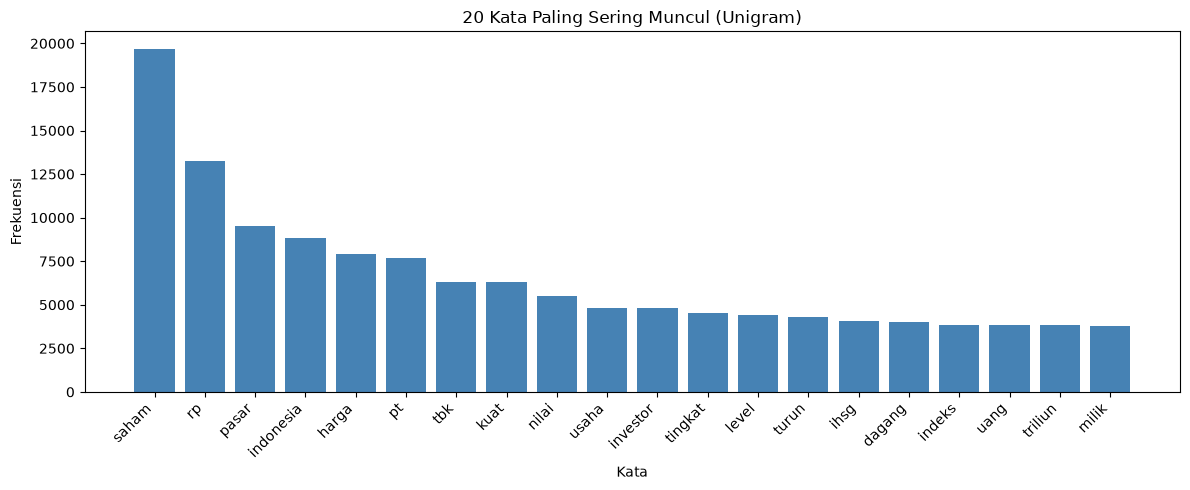

In [58]:
#Visualisasi
import matplotlib.pyplot as plt

# Top 20 unigram
top_words = unigram.most_common(20)
words_list = [w[0] for w in top_words]
counts_list = [w[1] for w in top_words]

plt.figure(figsize=(12, 5))
plt.bar(words_list, counts_list, color="steelblue")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Kata")
plt.ylabel("Frekuensi")
plt.title("20 Kata Paling Sering Muncul (Unigram)")
plt.tight_layout()
plt.show()